In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/dataset.csv"
OUTPUT_DIR = "../output"
os.makedirs(f"{OUTPUT_DIR}/figures", exist_ok=True)
RANDOM_STATE = 42

In [2]:
# Data Analysis and Preprocessing
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Shape: (50000, 2)
Columns: ['review', 'sentiment']


In [3]:
print(df.dtypes)
df.info()
display(df.describe(include="all"))
print(df["sentiment"].value_counts())

review       str
sentiment    str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
print("Missing values per column:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
 review       0
sentiment    0
dtype: int64
Duplicate rows: 418


In [5]:
shape_before = df.shape
df = df.drop_duplicates().reset_index(drop=True)
print("Shape before:", shape_before)
print("Shape after: ", df.shape)
print(df["sentiment"].value_counts())

Shape before: (50000, 2)
Shape after:  (49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [6]:
long_positive = df.loc[(df["sentiment"] == "positive") & (df["review"].str.len() > 2000)]
print(len(long_positive), "long positive reviews")
long_positive.head()

4368 long positive reviews


,review,sentiment
26,"""The Cell"" is an exotic masterpiece, a dizzyin...",positive
29,'War movie' is a Hollywood genre that has been...,positive
30,"Taut and organically gripping, Edward Dmytryk'...",positive
31,"""Ardh Satya"" is one of the finest film ever ma...",positive
33,One of the most significant quotes from the en...,positive


In [7]:
df.iloc[0:7]

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive


In [8]:
df.iloc[np.r_[0:3, 100:103]]

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
100,This short film that inspired the soon-to-be f...,positive
101,"Okay, last night, August 18th, 2004, I had the...",negative
102,I bought this game on an impulse buy from walm...,positive


In [9]:
df["label"] = df["sentiment"].replace({"negative": 0, "positive": 1}) 
df

,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1
...,...,...,...
49577,I thought this movie did a down right good job...,positive,1
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,0
49579,I am a Catholic taught in parochial elementary...,negative,0
49580,I'm going to have to disagree with the previou...,negative,0


In [10]:
df["sentiment"] = df["sentiment"].astype("category")
df["label"] = df["label"].astype(int)

In [11]:
df["char_count"] = df["review"].str.len() 
df["word_count"] = df["review"].str.split().str.len()
df

,review,sentiment,label,char_count,word_count
0,One of the other reviewers has mentioned that ...,positive,1,1761,307
1,A wonderful little production. <br /><br />The...,positive,1,998,162
2,I thought this was a wonderful way to spend ti...,positive,1,926,166
3,Basically there's a family where a little boy ...,negative,0,748,138
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1,1317,230
...,...,...,...,...,...
49577,I thought this movie did a down right good job...,positive,1,1008,194
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,0,642,112
49579,I am a Catholic taught in parochial elementary...,negative,0,1280,230
49580,I'm going to have to disagree with the previou...,negative,0,1234,212


In [12]:
N = 5000
simple = df.sample(n=N, random_state=RANDOM_STATE)
print(len(simple))

5000


In [13]:
stratified = (
    df.groupby("sentiment")
      .sample(frac=N / len(df), random_state=RANDOM_STATE)
)

print(len(stratified))

5000


In [14]:
df["cluster_id"] = np.arange(len(df)) // (len(df) // 100)
rng = np.random.default_rng(RANDOM_STATE)
chosen = rng.choice(df["cluster_id"].unique(), size=10, replace=False)
cluster = df[df["cluster_id"].isin(chosen)]
print("clusters chosen:", sorted(chosen), "| rows:", len(cluster))

clusters chosen: [np.int64(8), np.int64(9), np.int64(20), np.int64(41), np.int64(61), np.int64(69), np.int64(71), np.int64(83), np.int64(95), np.int64(97)] | rows: 4950


In [15]:
comparison = pd.DataFrame({
    "original": df["sentiment"].value_counts(normalize=True),
    "simple": simple["sentiment"].value_counts(normalize=True),
    "stratified": stratified["sentiment"].value_counts(normalize=True),
    "cluster": cluster["sentiment"].value_counts(normalize=True),
}).round(4)
display(comparison)
print({"simple": len(simple), "stratified": len(stratified), "cluster": len(cluster)})

,original,simple,stratified,cluster
sentiment,,,,
negative,0.4981,0.502,0.4982,0.499
positive,0.5019,0.498,0.5018,0.501


{'simple': 5000, 'stratified': 5000, 'cluster': 4950}


In [16]:
df["unique_word_count"] = df["review"].str.lower().str.split().apply(lambda w: len(set(w)))
df["avg_word_length"] = df["char_count"] / df["word_count"]

features = ["char_count", "word_count", "unique_word_count", "avg_word_length"]
df[features].describe().head()

,char_count,word_count,unique_word_count,avg_word_length
count,49582.000000,49582.000000,49582.000000,49582.000000
mean,1310.568230,231.350167,148.145658,5.634475
std,990.762238,171.542020,88.897414,0.340699
min,32.000000,4.000000,4.000000,2.236486
25%,699.000000,126.000000,91.000000,5.411765


In [17]:
num_cols = features + ["label"]
corr = df[num_cols].corr()
corr.round(3)

,char_count,word_count,unique_word_count,avg_word_length,label
char_count,1.000,0.997,0.990,0.182,0.016
word_count,0.997,1.000,0.987,0.120,0.010
unique_word_count,0.990,0.987,1.000,0.179,0.000
avg_word_length,0.182,0.120,0.179,1.000,0.051
label,0.016,0.010,0.000,0.051,1.000


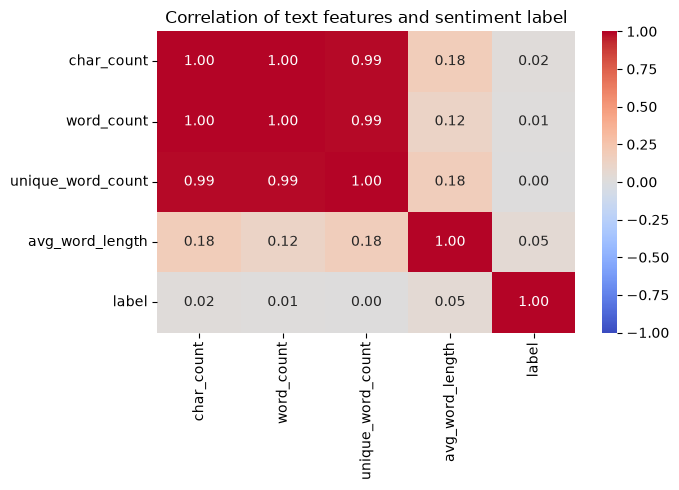

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of text features and sentiment label")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/correlation_heatmap.png", dpi=150)
plt.show()

In [19]:
# Data anlysis done